In [1]:
import os, glob
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
name = os.path.split(os.getcwd())[1]
pth = os.path.join('..', '..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', name)
pth_cb = os.path.join(pth_out, 'colorbars')

In [3]:
# load processed data from h5ad file
fn = os.path.join(pth_in, 'processed.h5ad')
adata = sc.read_h5ad(fn); adata

AnnData object with n_obs × n_vars = 2356 × 20435
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'celltype', 'leiden'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'celltype_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'sample_colors', 'source_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [4]:
# build dictionary with EMT module names (keys) + genes (vals)
feat_fn = sorted(glob.glob(os.path.join(pth_feat, '*.csv')))
get_src = lambda fn: os.path.split(fn)[1].replace('.csv', '')
get_feat = lambda fn: pd.read_csv(fn).hsapiens.drop_duplicates()
feat_dict = {get_src(fn) : get_feat(fn) for fn in feat_fn}

# compute EMT module signatures across the dataset
msk_ref = feat_dict['union'].isin(adata.var_names)
g_ref = feat_dict['union'].loc[msk_ref].copy()
for src, df_src in feat_dict.items():
    if src != 'union':
        msk = df_src.isin(adata.var_names)
        g = df_src.loc[msk].copy()
        sc.tl.score_genes(adata,
                          gene_list = g,
                          score_name = src,
                          ctrl_as_ref = False,
                          gene_pool = g_ref,
                          random_state = 1234)
        print(src, g.size, g_ref.size)

GSE162534 78 231
GSE229103 92 231
rRNAModifications 103 231


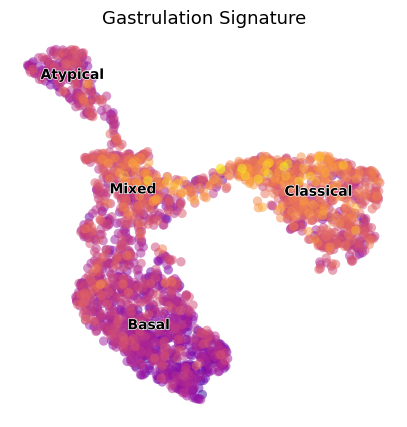

In [5]:
# save gastrulation signature figure
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 'GSE162534',
           cmap = 'plasma', alpha = .5,
           size = 180, colorbar_loc = None,
           frameon = False, show = False,
           ax = ax)
sc.pl.umap(adata, color = 'celltype', size = 180,
           alpha = 0, legend_loc = 'on data',
           legend_fontoutline = 1, frameon = False,
           show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Gastrulation Signature', size = 13)
fn = os.path.join(pth_out, 'Gast_signature.pdf')
plt.savefig(fn, bbox_inches = 'tight')

/tmp/ipykernel_1934790/1532992161.py:4: UserWarning: Adding colorbar to a different Figure <Figure size 500x500 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[0], cax = cax)


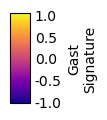

In [6]:
# save gastrulation signature colorbar
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax = cax)
cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('Gast\nSignature')
ticks = np.asarray([-1, -.5, 0, .5, 1])
cb.set_ticks(ticks, labels = ticks)
cb.solids.set_alpha(1)
fn = os.path.join(pth_cb, 'Gast_colorbar.pdf')
plt.savefig(fn, bbox_inches = 'tight')

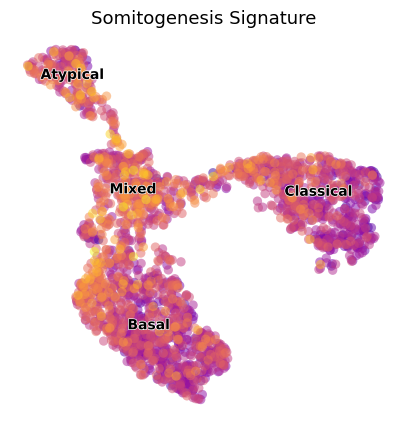

In [7]:
# save somitogenesis signature figure
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 'GSE229103',
           cmap = 'plasma', alpha = .5,
           size = 180, colorbar_loc = None,
           frameon = False, show = False,
           ax = ax)
sc.pl.umap(adata, color = 'celltype', size = 180,
           alpha = 0, legend_loc = 'on data',
           legend_fontoutline = 1, frameon = False,
           show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Somitogenesis Signature', size = 13)
fn = os.path.join(pth_out, 'pSom_signature.pdf')
plt.savefig(fn, bbox_inches = 'tight')

/tmp/ipykernel_1934790/3426888087.py:4: UserWarning: Adding colorbar to a different Figure <Figure size 500x500 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[0], cax = cax)


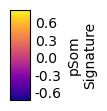

In [8]:
# save somitogenesis signature colorbar
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax = cax)
cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('pSom\nSignature')
ticks = np.asarray([-.6, -.3, 0, .3, .6])
cb.set_ticks(ticks, labels = ticks)
cb.solids.set_alpha(1)
fn = os.path.join(pth_cb, 'pSom_colorbar.pdf')
plt.savefig(fn, bbox_inches = 'tight')

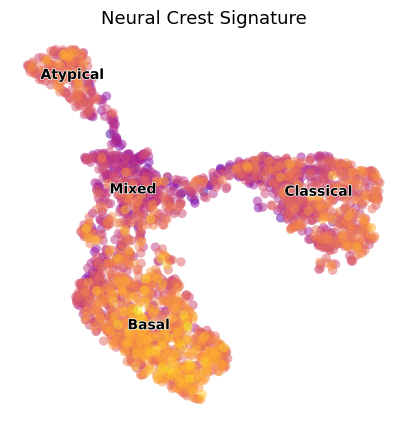

In [9]:
# save neural crest signature figure
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 'rRNAModifications',
           cmap = 'plasma', alpha = .5,
           size = 180, colorbar_loc = None,
           frameon = False, show = False,
           ax = ax)
sc.pl.umap(adata, color = 'celltype', size = 180,
           alpha = 0, legend_loc = 'on data',
           legend_fontoutline = 1, frameon = False,
           show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Neural Crest Signature', size = 13)
fn = os.path.join(pth_out, 'Crest_signature.pdf')
plt.savefig(fn, bbox_inches = 'tight')

/tmp/ipykernel_1934790/2153504045.py:4: UserWarning: Adding colorbar to a different Figure <Figure size 500x500 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[0], cax = cax)


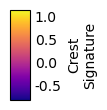

In [10]:
# save neural crest signature colorbar
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax = cax)
cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('Crest\nSignature')
ticks = np.asarray([-.5, 0, .5, 1])
cb.set_ticks(ticks, labels = ticks)
cb.solids.set_alpha(1)
fn = os.path.join(pth_cb, 'Crest_colorbar.pdf')
plt.savefig(fn, bbox_inches = 'tight')

In [11]:
# save signatures data to h5ad file
adata.write(os.path.join(pth_in, 'signatures.h5ad'))